In [1]:
#相关函数定义：激活函数和损失函数，和对一个函数的导数
import numpy as np
# from sklearn import datasets

def sigmod(z):
    h = 1./(1+np.exp(-z))
    return h
    
def de_sigmoid(z,h):
    return h*(1-h)
    
    
def relu(z):
    h = np.maximum(z, 0)
    return h
    
def de_relu(z,h):
    z[z <= 0] = 0
    z[z > 0] = 1.0
    return z
    
    
def no_active(z):
    h = z
    return h

def de_no_active(z,h):
    return np.ones(h.shape)
    
# o Nxc
# lab Nxc    
def loss_L2(o,lab):
    diff = lab-o
    sqrDiff = diff ** 2
    return 0.5*np.sum(sqrDiff)
    
def de_loss_L2(o,lab):
    return o-lab


def loss_CE(o,lab):    
    p = np.exp(o)/np.sum(np.exp(o),axis=1,keepdims=True)
    loss_ce = np.sum(-lab*np.log(p))
    return loss_ce

def de_loss_CE(o,lab):
    p = np.exp(o)/np.sum(np.exp(o),axis=1,keepdims=True)
    return p-lab

In [2]:
#构建网络 ：返回一个list : 包含了各层每一层的w，b，激活函数和反向函数
def bulid_net(dim_in,list_num_hidden,list_act_funs,list_de_act_funs):
    # dim_in:int:输入特征的维度
    # list_num_hidden：list: 每层输出节点的数目(每层神经元的数目，矩阵的列数)
    # list_act_funs： 每层的激活函数
    # list_de_act_funs: 反向传播时的函数
    layers=[]
    
    # 逐层的进行网络构建
    for i in range(len(list_num_hidden)):
        layer = {}
        
        # 定义每一层的权重:w
        if i ==0:
            # layer["w"]= 0.2*np.random.randn(dim_in,list_num_hidden[i])-0.1 # 用sigmoid激活函数
            layer["w"]= 0.01*np.random.randn(dim_in,list_num_hidden[i])  # 用relu 激活函数
        else:
            # layer["w"]= 0.2*np.random.randn(list_num_hidden[i-1],list_num_hidden[i])-0.1 # 用sigmoid激活函数
            layer["w"]= 0.01*np.random.randn(list_num_hidden[i-1],list_num_hidden[i]) # 用relu 激活函数
        
        # 定义每一层的偏置。应该是每一个神经元都定义了一个b
        layer["b"] = 0.1*np.ones([1,list_num_hidden[i]])
        layer["act_fun"]= list_act_funs[i]
        layer["de_act_fun"]= list_de_act_funs[i]
        layers.append(layer)
        
    return layers

In [3]:
#前馈计算 : 返回每一层的输入(input_layers),每一层的线性计算结果(input_acfun) 和 最后一层的输出(h)
def fead_forward(datas,layers):
    #datas : 输入矩阵
    #layers : 神经网络
    
    input_layers = []
    input_acfun = []
    for i in range(len(layers)):
        layer = layers[i]
        if i ==0:
            inputs = datas
            z = np.dot(inputs,layer["w"]) + layer["b"]
            h = layer['act_fun'](z)
            input_layers.append(inputs)
            input_acfun.append(z)
        else:
            inputs = h
            z = np.dot(inputs,layer["w"])+ layer["b"]
            h = layer['act_fun'](z)
            input_layers.append(inputs)
            input_acfun.append(z)
    return input_layers,input_acfun,h

In [4]:
# 进行反向参数更新 一次 ，返回网络和 本次正向计算的损失 
def updata_wb(datas,labs,layers, loss_fun,de_loss_fun,alpha=0.01):
    N,D = np.shape(datas)
    # 进行前馈操作
    inputs,input_acfun,output = fead_forward(datas,layers)
    # 计算 loss
    loss = loss_fun(output,labs)
    #从后向前计算
    deltas0 = de_loss_fun(output,labs)
    # 从后向前计算误差
    deltas =[]
    for i in range(len(layers)):
        index = -i-1
        if i ==0:
            h = output
            z = input_acfun[index]
            delta = deltas0*layers[index]["de_act_fun"](z,h)
        else:
            h = inputs[index+1]
            z = input_acfun[index]
            # print(layers[index]["de_act_fun"](z,h)[1])
            delta = np.dot(delta,layers[index+1]["w"].T)*layers[index]["de_act_fun"](z,h)
        
        deltas.insert(0,delta)
    
    # 利用误差 对每一层的权重进行修成
    for i in range(len(layers)):
        # 计算 dw 与 db
        dw = np.dot(inputs[i].T,deltas[i])
        db = np.sum(deltas[i],axis=0,keepdims=True)
        # 梯度下降
        layers[i]["w"] = layers[i]["w"] - alpha*dw
        layers[i]["b"] = layers[i]["b"] - alpha*db
        
    return layers,loss

In [5]:
# 使用网络进行计算得出结果的正确率
def test_accuracy(datas,labs_true,layers):
    _,_,output = fead_forward(datas,layers)
    lab_det = np.argmax(output,axis=1)
    labs_true = np.argmax(labs_true,axis=1) 
    N_error = np.where(np.abs(labs_true-lab_det)>0)[0].shape[0]
   
    error_rate = N_error/np.shape(datas)[0]
    return error_rate

In [114]:
#初始化数据，拆分成训练集和测试集，分类和代码的mapping
def load_dataset_iris(file_data,N_train):
    # 数据读取
    datas = np.loadtxt(file_data,dtype = np.float64, delimiter = ',',usecols=(0,1,2,3))
    labs = np.loadtxt(file_data,dtype = str, delimiter = ',',usecols=(4))
    N,D = np.shape(datas)
    N_test = N-N_train
    unqiue_labs = np.unique(labs).tolist()
    
    dic_str2index={}
    dic_index2str={}
    for i in range(len(unqiue_labs)): # 给dic_index2str赋值：不同的序号对应不同的种类值
        lab_str = unqiue_labs[i]
        dic_str2index[lab_str] =i
        dic_index2str[i]=lab_str
    
    labs_onehot = np.zeros([N,len(unqiue_labs)])
    for i in range(N):
        labs_onehot[i,dic_str2index[labs[i]]]=1
    
    perm = np.random.permutation(N) #数据打乱后的序号
    index_train = perm[:N_train]
    index_test = perm[N_train:]

    data_train = datas[index_train,:]
    lab_train_onehot = labs_onehot[index_train,:]

    data_test = datas[index_test,:]
    lab_test_onehot = labs_onehot[index_test]

    return data_train,lab_train_onehot,data_test,lab_test_onehot,dic_index2str

In [181]:
#拆分数据
data_train,lab_train_onehot,data_test,lab_test_onehot,dic_index2str =load_dataset_iris(file_data,100)

In [234]:
if __name__=="__main__":
    file_data = 'D:/pyprj/cv2/data/iris.data'
    # global layers
    # iris = datasets.load_iris()
    # iris_data = np.hstack((iris.data,iris.target.reshape(-1,1)))
    
    # data_train,lab_train_onehot,data_test,lab_test_onehot,dic_index2str =load_dataset_iris(file_data,100)
    
    N,dim_in = np.shape(data_train)
    # 定义网络结构
    list_num_hidden=[4,4,3]
    list_act_funs =[relu,relu,no_active]
    list_de_act_funs=[de_relu,de_relu,de_no_active]
    
    # 定义损失函数
    # loss_fun = loss_CE
    # de_loss_fun=de_loss_CE
    
    loss_fun = loss_L2
    de_loss_fun=de_loss_L2
    
    layers = bulid_net(dim_in,list_num_hidden,
          list_act_funs,list_de_act_funs)
    
   
    # 进行训练
    n_epoch = 100
    batchsize =4
    N_batch = N//batchsize
    for i in range(n_epoch):
        # 数据打乱
        rand_index  = np.random.permutation(N).tolist()
        # 每个batch 更新一下weight
        loss_sum =0
        for j in range(N_batch):
            index = rand_index[j*batchsize:(j+1)*batchsize]
            batch_datas = data_train[index]
            batch_labs = lab_train_onehot[index]
            layers,loss = updata_wb(batch_datas,batch_labs,layers,loss_fun,de_loss_fun,alpha=0.01)
            loss_sum = loss_sum+loss
            
        error = test_accuracy(data_train,lab_train_onehot,layers)
        # print("epoch %d  error  %.2f%%  loss_all %.2f"%(i,error*100,loss_sum))
    
    #进行测试
    error = test_accuracy(data_test,lab_test_onehot,layers)
    print(error*100)



28.000000000000004


In [211]:
w1 = layers[0]['w']
w2 = layers[1]['w']
w3 = layers[2]['w']
layers1 = layers

In [212]:
w11 = layers[0]['w']
w22 = layers[1]['w']
w33 = layers[2]['w']
layers2 = layers

In [213]:
mod1 = np.linalg.norm(w1,axis=0)
mod2 = np.linalg.norm(w2,axis=0)
mod3 = np.linalg.norm(w3,axis=0)
mod11 = np.linalg.norm(w11,axis=0)
mod22 = np.linalg.norm(w22,axis=0)
mod33 = np.linalg.norm(w33,axis=0)

In [214]:
w1_1 = w1.T/mod1.reshape(-1,1)
w2_1 = w2.T/mod2.reshape(-1,1)
w3_1 = w3.T/mod3.reshape(-1,1)
w11_1 = w11.T/mod11.reshape(-1,1)
w22_1 = w22.T/mod22.reshape(-1,1)
w33_1 = w33.T/mod33.reshape(-1,1)

In [231]:
np.savetxt('/ts3.csv',X=np.hstack((data_train@w1_1.T@w2_1.T@w3_1.T,np.argmax(lab_train_onehot,axis=1).reshape(-1,1),o3.reshape(-1,1) )),delimiter=',')

In [220]:
data_train@w1_1.T

array([[-1.72733916e+00, -1.41709649e+00,  2.39016044e+00,
        -1.55096307e+00, -1.40005907e+00,  2.57480256e+00,
         2.31276949e+00, -1.29615050e+00],
       [-1.80421761e+00, -1.53199839e+00,  2.35896070e+00,
        -1.66150085e+00, -1.51958944e+00,  2.52856341e+00,
         2.32556164e+00, -1.42975042e+00],
       [ 5.99119399e-01,  9.43110250e-01,  3.24298015e-01,
         7.46560596e-01,  9.34848830e-01,  5.85572460e-01,
         2.85167597e-01,  1.06976350e+00],
       [ 6.24354880e-01,  8.96960626e-01,  2.30707827e-01,
         7.32530824e-01,  8.81976854e-01,  4.53521548e-01,
         1.79318759e-01,  1.00180597e+00],
       [-1.78833811e+00, -1.49535969e+00,  2.41507712e+00,
        -1.61916372e+00, -1.47825310e+00,  2.58709042e+00,
         2.33591518e+00, -1.38006127e+00],
       [ 1.76312299e+00,  2.11700684e+00, -6.43956928e-01,
         1.90569384e+00,  2.09680161e+00, -3.54264540e-01,
        -7.17413259e-01,  2.25188546e+00],
       [ 1.74235195e+00,  2.113444

In [230]:
np.hstack((data_train@w1_1.T@w2_1.T@w3_1.T,np.argmax(lab_train_onehot,axis=1).reshape(-1,1),o3.reshape(-1,1) ))

array([[  7.02865581,   0.68531623,  -7.32326957,   0.        ,
          0.        ],
       [  7.33897675,   0.60824749,  -7.49614256,   0.        ,
          0.        ],
       [ -2.17810127,   0.72665346,   0.95856011,   1.        ,
          1.        ],
       [ -2.18221333,   0.63896818,   1.08486136,   1.        ,
          1.        ],
       [  7.27552937,   0.65647383,  -7.50661634,   0.        ,
          0.        ],
       [ -6.71918649,   0.77483899,   5.00414816,   2.        ,
          2.        ],
       [ -6.83081062,   0.71711237,   5.18545888,   2.        ,
          2.        ],
       [ -7.91552583,   0.6735563 ,   6.22864445,   2.        ,
          2.        ],
       [ -2.5726378 ,   0.52427332,   1.59872856,   1.        ,
          1.        ],
       [  7.34830205,   0.63813187,  -7.5465315 ,   0.        ,
          0.        ],
       [  5.99408602,   0.54924669,  -6.19588443,   0.        ,
          0.        ],
       [ -4.00236175,   0.60589317,   2.779

In [227]:
o1,o2,o3 = fead_forward(data_train,layers)
o3 = np.argmax(o3,axis=1)
o3

array([0, 0, 1, 1, 0, 2, 2, 2, 1, 0, 0, 1, 0, 1, 2, 1, 2, 2, 1, 1, 2, 1,
       0, 2, 2, 1, 2, 2, 2, 1, 0, 1, 0, 2, 1, 2, 2, 2, 1, 2, 0, 0, 1, 2,
       0, 2, 1, 2, 2, 0, 2, 1, 1, 2, 0, 1, 0, 2, 0, 2, 0, 1, 2, 0, 1, 2,
       0, 2, 0, 2, 1, 0, 2, 1, 1, 0, 0, 0, 1, 2, 0, 2, 2, 0, 2, 1, 0, 2,
       0, 1, 2, 1, 1, 0, 0, 0, 2, 0, 0, 1])

In [203]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

In [204]:
o=np.argmax(lab_train_onehot,axis=1)
o1,o2,o3 = fead_forward(data_train,layers)
o3 = np.argmax(o3,axis=1)

In [205]:
np.hstack((o[:,np.newaxis],o3.reshape(-1,1),np.arange(1,len(o)+1 ).reshape(-1,1)))

array([[  0,   0,   1],
       [  0,   0,   2],
       [  1,   1,   3],
       [  1,   1,   4],
       [  0,   0,   5],
       [  2,   1,   6],
       [  2,   1,   7],
       [  2,   2,   8],
       [  1,   1,   9],
       [  0,   0,  10],
       [  0,   0,  11],
       [  1,   1,  12],
       [  0,   0,  13],
       [  1,   1,  14],
       [  2,   1,  15],
       [  1,   1,  16],
       [  2,   1,  17],
       [  2,   1,  18],
       [  1,   1,  19],
       [  1,   1,  20],
       [  2,   2,  21],
       [  1,   1,  22],
       [  0,   0,  23],
       [  2,   2,  24],
       [  2,   2,  25],
       [  1,   1,  26],
       [  1,   1,  27],
       [  2,   1,  28],
       [  2,   2,  29],
       [  1,   1,  30],
       [  0,   0,  31],
       [  1,   1,  32],
       [  0,   0,  33],
       [  2,   1,  34],
       [  1,   1,  35],
       [  2,   1,  36],
       [  2,   1,  37],
       [  2,   2,  38],
       [  1,   1,  39],
       [  2,   1,  40],
       [  0,   0,  41],
       [  0,   0

In [121]:
df1 = pd.DataFrame(np.hstack((o[:,np.newaxis],o3.reshape(-1,1),np.arange(1,len(o)+1 ).reshape(-1,1))),columns=['x1','x2','x'])


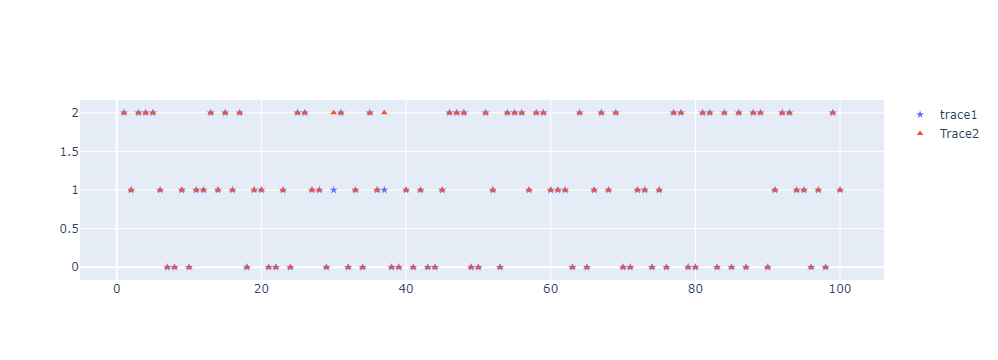

In [209]:
trace1 = px.scatter(df1,x='x',y='x1')
trace1.for_each_trace(
    lambda trace: trace.update(name="trace1",marker=dict(symbol=['star']*len(df1)),showlegend=True) 
)
# trace1.update_traces(
#     marker=dict(
#         symbol=['star']*len(df1)),name='trace1')

trace2 = go.Scatter(x=df1['x'],y=df1['x2'],name='Trace2',mode='markers',marker=dict(symbol='triangle-up') )
fig = go.Figure(data=trace1.data+tuple([trace2]))
fig.show()

In [ ]:
np.sum(o3,axis=1)
deltas0 = lab_train_onehot - o3

deltas0*layers[2]["de_act_fun"](z,h)


In [13]:
# h = output
# z = input_acfun[index]
# delta = deltas0*layers[index]["de_act_fun"](z,h)
o2[2]

array([[ 9.49303959e-01,  4.84981866e-02,  2.50785042e-03],
       [-7.17211874e-03,  3.86535231e-02,  9.69726047e-01],
       [ 1.72294389e-02,  1.00502556e+00, -2.83183423e-02],
       [-1.02809605e-02, -1.08732962e-01,  1.12090856e+00],
       [ 5.91119543e-03,  8.37142340e-01,  1.55350033e-01],
       [-6.90258428e-03,  5.12987185e-02,  9.56759606e-01],
       [ 1.59590392e-02,  1.00449510e+00, -2.61591924e-02],
       [ 9.73687770e-01,  2.34746701e-02,  3.31428813e-03],
       [ 1.05173520e+00, -5.66203244e-02,  5.89552501e-03],
       [-8.08972981e-03, -4.77005792e-03,  1.01426538e+00],
       [-2.20666022e-03,  2.95479764e-01,  7.06860062e-01],
       [ 1.64200522e-02,  1.00585618e+00, -2.83451109e-02],
       [ 9.60536443e-01,  3.69710198e-02,  2.87933866e-03],
       [-4.73094664e-03,  1.54209492e-01,  8.51199773e-01],
       [-2.15049614e-03,  3.39932500e-01,  6.62346801e-01],
       [-2.79366111e-03,  2.62450184e-01,  7.40599710e-01],
       [ 1.01400463e+00, -1.78998960e-02

In [14]:
o1,o2,o3 = fead_forward(data_test[:,:],layers=layers)
len(np.where((np.argmax(o3,axis=1)-np.argmax(lab_test_onehot,axis=1))!=0)[0])

1

In [ ]:
w = layers[0]['w']
w = w/np.linalg.norm(w,axis=0)


arr3 = np.linalg.norm(data_train,axis=1)
arr3 = data_train/arr3.reshape(-1,1)
arr4 = arr3@arr3.T
arr4 = arr3@w
pd.DataFrame(arr4).to_excel("d:/dataxw.xlsx")

In [ ]:
w = layers[0]['w']
print(w)
w = w/np.linalg.norm(w,axis=0)
print(w[:,0]@w[:,0])

In [ ]:
import pygwalker as pyg
import pandas as pd
lab_true = np.argmax(lab_train_onehot,axis=1)
lab_hat = np.argmax(o3,axis=1)

In [ ]:
w = layers[0]['w'].T
t = np.hstack((data_train,lab_true.reshape(-1,1)))
t = np.vstack((t,np.hstack((w,np.ones((10,1))*3 ))))
df = pd.DataFrame(t,columns=['col1','col2','col3','col4','col5'])
df

In [ ]:
import pygwalker as pyg
pyg.walk(df)

In [ ]:
# 第1层的 的第一列w 最靠近 data_train中的哪个向量，最垂直于哪些向量
t = data_train@layers[0]['w']
order1 = np.argsort(t[:,0],axis=0)
lab_true[order1]


In [ ]:
w2 = layers[0]['w'].T
pd.DataFrame(np.vstack((w,w2))).to_excel('D:/w3.xlsx')

In [ ]:
pd.DataFrame(data_train@data_train.T).to_excel('d:/data.xlsx')

In [ ]:
train_true = np.argmax(lab_train_onehot,axis=1)
s1 = np.argsort(train_true)
data = data_train[s1]
data = data@data.T
data = np.vstack((train_true[s1].reshape(1,-1),data))
pd.DataFrame(data).to_excel('D:/data.xlsx')


In [ ]:
t1 = data_test[0:1,:]@layers[0]['w'] + layers[0]['b']

In [ ]:
layers[1]['w']

In [ ]:
t1[t1<0] = 0

In [ ]:
t2 = t1@layers[1]['w'] + layers[1]['b']

In [ ]:
t2[t2<0] = 0

In [ ]:
t3 = t2@layers[2]['w'] + layers[2]['b']

In [ ]:
t3

In [ ]:
lab_det = np.argmax(h,axis=1)
lab_ts = np.argmax(lab_test_onehot,axis=1)
lab_det,lab_ts


In [ ]:
layers

In [ ]:
from sklearn.datasets import fetch_20newsgroups

# 加载所有类别的数据集
newsgroups_all = fetch_20newsgroups(subset='all')

# 查看数据集的大小和类别数量
print("数据集大小：", len(newsgroups_all.data))
print("类别数量：", len(newsgroups_all.target_names))

# 打印第一篇文章的内容和对应的类别标签
print("第一篇文章的内容：", newsgroups_all.data[0])
print("对应的类别标签：", newsgroups_all.target[0])
